# EV Battery Health Prediction: Step 1, Loading the NASA Battery Data

This is the first notebook of my EV battery health project. Here I load the NASA Li-ion battery aging data for one battery (**B0005**), pull out the information I need from each discharge cycle, calculate the **State of Health (SOH)** and plot how the battery degrades over time.

**Project plan**

| Step | What I do |
|---|---|
| **1 (this notebook)** | **Load the NASA data for one battery, calculate SOH, plot the capacity fade** |
| 2 | Combine 4 batteries and explore the data |
| 3 | Train models to predict SOH |
| 4 | Explain the best model with SHAP |
| 5 | Predict Remaining Useful Life (RUL) |
| 6 | Build and deploy a Streamlit app |

## 1. About the dataset

The data comes from the **NASA Prognostics Center of Excellence (PCoE)** Li-ion battery aging dataset. The batteries were repeatedly **charged, discharged and measured (impedance)** in a lab until they wore out, so each file is a full run-to-failure record of one battery.

Each battery is stored as a MATLAB `.mat` file. Inside, every cycle is labelled as `charge`, `discharge` or `impedance`, and has its own measurements (voltage, current, temperature, time).

The measurement I care most about is **capacity (Ah)**. It is recorded for each discharge cycle and tells how much charge the battery could deliver. As a battery ages, this number goes down.

## 2. Importing libraries

- `numpy`, `pandas` for the data
- `matplotlib` for plots
- `scipy.io.loadmat` to read MATLAB `.mat` files

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from scipy.io import loadmat

## 3. Loading the `.mat` file

I started with **B0005**. The file sits in the `data/` folder of my project.

In [2]:
BATTERY = "B0005"
FILE_PATH = f"data/{BATTERY}.mat"

mat = loadmat(FILE_PATH)

# The battery's data sits under a key with the battery's name
cycles = mat[BATTERY][0, 0]["cycle"][0]

print("Total cycles in the file:", len(cycles))

Total cycles in the file: 616


## 4. What is inside the file?

Before extracting anything, I checked what kinds of cycles the file contains and what each one stores.

In [3]:
# How many cycles of each type?
type_counts = Counter(c["type"][0] for c in cycles)
print(type_counts)

Counter({np.str_('impedance'): 278, np.str_('charge'): 170, np.str_('discharge'): 168})


In [4]:
# Look at the fields stored inside the first discharge cycle
first_discharge = next(c for c in cycles if c["type"][0] == "discharge")
print(first_discharge["data"][0, 0].dtype.names)

('Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity')


Each **discharge** cycle stores:

| Field | Meaning |
|---|---|
| `Voltage_measured` | Battery terminal voltage (V) |
| `Current_measured` | Current going out of the battery (A) |
| `Temperature_measured` | Battery temperature (degrees C) |
| `Time` | Time of each reading within the cycle (s) |
| `Capacity` | Capacity measured for the discharge (Ah) |

Capacity is a **single number per discharge cycle**, while voltage, current, temperature and time are **long lists of readings**. So to get one row per cycle, I need to summarise each list into a few numbers (average, minimum, maximum and so on).

## 5. Turning each discharge cycle into one row

I only keep the **discharge** cycles, because that is where the capacity is measured. For each one I calculate:

| Column | How it is calculated |
|---|---|
| `cycle` | Discharge cycle number (1, 2, 3, ...) |
| `capacity_ah` | The measured capacity |
| `avg_voltage`, `min_voltage` | Average and lowest voltage |
| `avg_current` | Average current |
| `avg_temp`, `max_temp` | Average and peak temperature |
| `discharge_time_s` | Length of the discharge, from the last time reading |

The `cycle` number here counts **only discharge cycles**, so it is not the same as the position in the original file (which also includes charge and impedance cycles).

In [5]:
def load_discharge_cycles(file_path, battery_name):
    """Read a NASA .mat file and return one row per discharge cycle."""
    mat = loadmat(file_path)
    cycles = mat[battery_name][0, 0]["cycle"][0]

    rows = []
    discharge_number = 0

    for cycle in cycles:
        if cycle["type"][0] != "discharge":
            continue

        discharge_number += 1
        d = cycle["data"][0, 0]

        voltage = d["Voltage_measured"][0]
        current = d["Current_measured"][0]
        temp = d["Temperature_measured"][0]
        time = d["Time"][0]
        capacity = d["Capacity"][0][0]

        rows.append(
            {
                "cycle": discharge_number,
                "capacity_ah": capacity,
                "avg_voltage": np.mean(voltage),
                "min_voltage": np.min(voltage),
                "avg_current": np.mean(current),
                "avg_temp": np.mean(temp),
                "max_temp": np.max(temp),
                "discharge_time_s": time[-1],
            }
        )

    return pd.DataFrame(rows)


df = load_discharge_cycles(FILE_PATH, BATTERY)
print("Shape:", df.shape)
df.head()

Shape: (168, 8)


,cycle,capacity_ah,avg_voltage,min_voltage,avg_current,avg_temp,max_temp,discharge_time_s
0,1,1.856487,3.529829,2.612467,-1.818702,32.572328,38.982181,3690.234
1,2,1.846327,3.537320,2.587209,-1.817560,32.725235,39.033398,3672.344
2,3,1.835349,3.543737,2.651917,-1.816487,32.642862,38.818797,3651.641
3,4,1.835263,3.543666,2.592948,-1.825589,32.514876,38.762305,3631.563
4,5,1.834646,3.542343,2.547420,-1.826114,32.382349,38.665393,3629.172


## 6. Calculating State of Health (SOH)

SOH tells how much of its original capacity the battery still has:

`SOH (%) = current capacity / starting capacity x 100`

The first discharge cycle is the "starting capacity", so the first SOH value is exactly 100%. In EV use, a battery is commonly treated as end of life once it falls to about **80% SOH**.

In [6]:
initial_capacity = df["capacity_ah"].iloc[0]
df["soh_percent"] = df["capacity_ah"] / initial_capacity * 100

print(f"Starting capacity: {initial_capacity:.3f} Ah")
print(f"Final capacity:    {df['capacity_ah'].iloc[-1]:.3f} Ah")
print(f"Final SOH:         {df['soh_percent'].iloc[-1]:.1f} %")

Starting capacity: 1.856 Ah
Final capacity:    1.325 Ah
Final SOH:         71.4 %


In [7]:
df.describe().round(3)

,cycle,capacity_ah,avg_voltage,min_voltage,avg_current,avg_temp,max_temp,discharge_time_s,soh_percent
count,168.000,168.000,168.000,168.000,168.000,168.000,168.000,168.000,168.000
mean,84.500,1.573,3.517,2.649,-1.807,32.791,39.845,3129.524,84.703
std,48.642,0.190,0.033,0.049,0.085,0.714,1.118,246.654,10.257
min,1.000,1.287,3.464,2.456,-1.939,31.330,37.801,2792.485,69.349
25%,42.750,1.390,3.487,2.636,-1.883,32.282,38.805,2901.344,74.874
50%,84.500,1.557,3.515,2.660,-1.817,32.857,40.081,3086.078,83.873
75%,126.250,1.769,3.551,2.683,-1.728,33.356,40.865,3323.231,95.296
max,168.000,1.856,3.564,2.700,-1.667,34.311,41.450,3690.234,100.000


## 7. Capacity fade and SOH plot

The left plot shows the raw capacity in Ah. The right plot shows the same thing as SOH %, with the 80% end-of-life line.

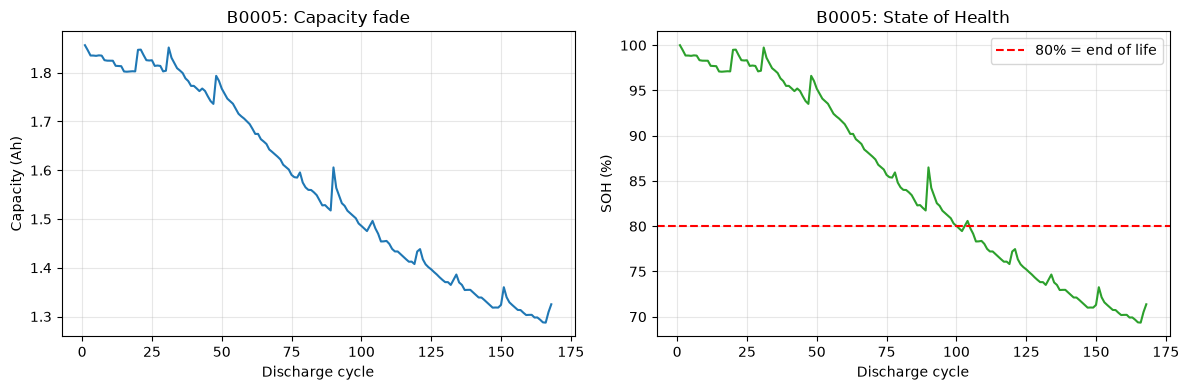

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df["cycle"], df["capacity_ah"], color="tab:blue")
axes[0].set_title(f"{BATTERY}: Capacity fade")
axes[0].set_xlabel("Discharge cycle")
axes[0].set_ylabel("Capacity (Ah)")
axes[0].grid(alpha=0.3)

axes[1].plot(df["cycle"], df["soh_percent"], color="tab:green")
axes[1].axhline(80, color="red", linestyle="--", label="80% = end of life")
axes[1].set_title(f"{BATTERY}: State of Health")
axes[1].set_xlabel("Discharge cycle")
axes[1].set_ylabel("SOH (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{BATTERY}_capacity_fade.png", dpi=150)
plt.show()

## 8. What I observed

- B0005 has **168 discharge cycles**. Its capacity falls from about **1.86 Ah to about 1.28 Ah**, so it loses roughly 30% of its starting capacity.
- The SOH curve crosses the **80% line at around cycle 100**, so by the common EV standard this battery is "worn out" at about that point, and the test continued well beyond it. That gives a full run-to-failure record, which is ideal for training a model.
- The curve is not perfectly smooth. There are **small upward spikes** at several points (for example around cycles 20, 30, 48, 90, 120 and 150). These look like the **capacity regeneration** effect: when a battery rests for a while, it can recover a little capacity, and then the long-term decline continues. The overall trend is still clearly downward.

These spikes are noise from the model's point of view, so I will keep them in mind when I train and evaluate models later.

## 9. Saving the cleaned table

I saved the per-cycle table so I can reuse it without reading the `.mat` file again.

In [9]:
df.to_csv(f"{BATTERY}_discharge_features.csv", index=False)
print("Saved:", f"{BATTERY}_discharge_features.csv")

Saved: B0005_discharge_features.csv


## 10. Next step

In Step 2 I will load all four batteries (B0005, B0006, B0007 and B0018) into one table, check the data quality, and explore which features change as the batteries age.